# Regional Search-Interest Pattern Segmentation Across Selected Topics Using Clustering

**Course:** CSE396 — Unsupervised Learning Project  
**Author:** Arjun (B.Tech Computer Science & Engineering)  
**Timeline:** 4-Day Progressive Development Plan  
**Current Milestone:** Day 2 — Data Preprocessing, Feature Scaling & Exploratory Data Analysis (EDA)  

---

## 1. Problem Statement & Real-Life Motivation

### Problem Statement
> *"Different geographic regions may have distinct patterns of information demand and search interest in emerging technologies, but manually identifying meaningful groups across many regions and technology topics is difficult."*

### Real-Life Motivation & Practical Applications
Regional information-seeking patterns reflect varying levels of curiosity and information demand across geographic areas. Discovering natural groups among Indian states can provide empirical evidence to guide:
1. **Targeted Technology Education Planning:** Identifying regions with emerging curiosity in specific domains (e.g., Cloud, AI, Cybersecurity) to tailor educational programs.
2. **Skill-Development & Workshop Roadmaps:** Guiding governmental and academic workshop roadmaps based on regional topic demand.
3. **Academic & Market Research:** Understanding regional variations in technology curiosity across India.

### Crucial Interpretation Safeguard:
> **IMPORTANT ETHICAL INTERPRETATION RULE:**  
> Google Trends search interest measures **relative search query volume on Google**, NOT actual knowledge, technological intelligence, education level, human competence, or adoption rate.
> - **Never claim:** *"Region X has poor AI knowledge or low tech competence."*  
> - **Accurate framing:** *"Region X showed relatively lower Google search interest for the selected AI-related search terms during the analyzed 12-month period."*  
> The clusters represent patterns in Google Trends search interest, never the capabilities of the people living in those regions.

## 2. Why Unsupervised Learning?

This project is formulated as an **unsupervised learning** problem because:
1. **Absence of Predefined Labels:** There are no pre-existing ground-truth categories telling us which Indian state belongs to which technology cluster.
2. **Natural Grouping Discovery:** The algorithm must independently discover latent groupings based purely on geometric similarity across regional topic search-interest profiles.
3. **Primary Algorithm:** **K-Means Clustering** will be used to partition states into coherent clusters, followed by validation metrics (Elbow Method / WCSS, Silhouette Analysis, Davies-Bouldin Index) and 2D visualization via Principal Component Analysis (PCA).

## 3. Dataset Scope & Selected Topics

- **Data Source:** Open Google Trends data retrieved via `pytrends` (official Trends endpoint).
- **Geographic Scope:** India (`geo='IN'`), state-level resolution (`resolution='REGION'`) covering all **36 States and Union Territories**.
- **Time Range:** Past 12 Months (`today 12-m`), reflecting recent sustained annual query curiosity.
- **Unit of Observation (Row):** Each row represents one Indian State or Union Territory.
- **Selected Emerging Technology Topics (8 Features):**
  1. `artificial_intelligence`: Artificial Intelligence
  2. `machine_learning`: Machine Learning
  3. `data_science`: Data Science
  4. `cloud_computing`: Cloud Computing
  5. `cybersecurity`: Cybersecurity
  6. `blockchain`: Blockchain
  7. `internet_of_things`: Internet of Things
  8. `chatgpt`: ChatGPT

### Methodological Note on Google Trends Normalization:
- Google Trends indices range from **0 to 100**, where 100 represents the region with peak relative search intensity for that topic, and other regions are scaled proportionally.
- In Day 2, numerical features will be standardized via `StandardScaler` to ensure scale uniformity for Euclidean distance in K-Means.

## 4. Google Trends Data Loading

The raw regional dataset was collected and saved to `data/raw/google_trends_raw_india.csv` using the standalone collection script (`src/data_collection.py`).  
Below, we load the raw dataset using portable relative paths.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Ensure portable relative paths
possible_paths = [
    os.path.join("..", "data", "raw", "google_trends_raw_india.csv"),
    os.path.join("data", "raw", "google_trends_raw_india.csv")
]

raw_data_path = None
for p in possible_paths:
    if os.path.exists(p):
        raw_data_path = p
        break

if raw_data_path is None:
    raise FileNotFoundError("Raw data file not found! Please run src/data_collection.py first.")

print(f"Loading raw data from: {raw_data_path}")
df_raw = pd.read_csv(raw_data_path)
print(f"Loaded successfully: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns.")

Loading raw data from: ..\data\raw\google_trends_raw_india.csv
Loaded successfully: 36 rows, 10 columns.


## 5. Day 1: Basic Dataset Inspection

Inspection of the raw dataset confirms observations across the 36 Indian administrative regions.

In [2]:
# Display sample records (First 5 and Last 5)
print("=== FIRST 5 ROWS ===")
display(df_raw.head())

print("=== LAST 5 ROWS ===")
display(df_raw.tail())

=== FIRST 5 ROWS ===


,state,geo_code,artificial_intelligence,machine_learning,data_science,cloud_computing,cybersecurity,blockchain,internet_of_things,chatgpt
0,Andaman and Nicobar Islands,IN-AN,57,39,26,39,43,89,0,71
1,Andhra Pradesh,IN-AP,68,96,77,100,71,68,87,78
2,Arunachal Pradesh,IN-AR,27,14,18,9,12,22,0,36
3,Assam,IN-AS,36,26,28,15,28,50,33,41
4,Bihar,IN-BR,34,28,35,18,27,39,40,26


=== LAST 5 ROWS ===


,state,geo_code,artificial_intelligence,machine_learning,data_science,cloud_computing,cybersecurity,blockchain,internet_of_things,chatgpt
31,Telangana,IN-TG,72,99,96,64,100,76,70,84
32,Tripura,IN-TR,43,34,38,24,35,52,43,39
33,Uttar Pradesh,IN-UP,48,47,47,32,42,55,45,41
34,Uttarakhand,IN-UT,48,48,50,34,40,46,41,57
35,West Bengal,IN-WB,40,45,50,23,37,53,37,40


In [3]:
# Dimensions, column types, and concise summary
print(f"Dataset Shape: {df_raw.shape} (Rows: {df_raw.shape[0]}, Columns: {df_raw.shape[1]})")
print("\n=== COLUMN DATA TYPES ===")
print(df_raw.dtypes)

Dataset Shape: (36, 10) (Rows: 36, Columns: 10)

=== COLUMN DATA TYPES ===
state                      object
geo_code                   object
artificial_intelligence     int64
machine_learning            int64
data_science                int64
cloud_computing             int64
cybersecurity               int64
blockchain                  int64
internet_of_things          int64
chatgpt                     int64
dtype: object


## 6. Day 2: Data Cleaning, Missing Value Audit & Duplicate Check

In this section, we rigorously audit the dataset for:
1. **Missing / Null Values:** Check for `NaN` entries across all columns.
2. **Zero-Value Analysis:** In Google Trends, a value of `0` indicates search volume below the logging threshold for that region/timeframe (common in smaller Union Territories), rather than corrupted data. We verify whether any state has completely missing or invalid data across all topics.
3. **Duplicate Records:** Check for duplicate rows and duplicate state identifiers.

In [4]:
# Audit missing values
print("=== MISSING / NULL VALUES AUDIT ===")
null_summary = df_raw.isnull().sum()
print(null_summary)
print(f"\nTotal Missing Values: {null_summary.sum()}")

# Audit duplicates
duplicate_rows = df_raw.duplicated().sum()
duplicate_states = df_raw["state"].duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_rows}")
print(f"Duplicate State Identifiers: {duplicate_states}")

# Audit zero values across numerical topic features
topic_cols = [c for c in df_raw.columns if c not in ["state", "geo_code"]]
zero_summary = (df_raw[topic_cols] == 0).sum()
print("\n=== ZERO VALUE COUNTS PER TOPIC ===")
print(zero_summary)

=== MISSING / NULL VALUES AUDIT ===
state                      0
geo_code                   0
artificial_intelligence    0
machine_learning           0
data_science               0
cloud_computing            0
cybersecurity              0
blockchain                 0
internet_of_things         0
chatgpt                    0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0
Duplicate State Identifiers: 0

=== ZERO VALUE COUNTS PER TOPIC ===
artificial_intelligence    1
machine_learning           1
data_science               1
cloud_computing            1
cybersecurity              1
blockchain                 1
internet_of_things         6
chatgpt                    0
dtype: int64


### Missing Value & Cleaning Decision:
- **No Nulls:** There are exactly 0 null/NaN values across all 36 regions.
- **No Duplicates:** All 36 rows represent unique administrative entities.
- **Zero Values:** Zero values appear in a few smaller Union Territories (e.g., Andaman and Nicobar, Arunachal Pradesh) primarily in specialized topics like `internet_of_things`. These represent genuine low relative search volume rather than collection failure.
- **Conclusion:** No imputation or row deletion is needed; the complete set of 36 Indian States and UTs is preserved.

## 7. Feature Selection & Identifier Separation

To prepare for clustering, we partition the dataset into:
1. **Identifiers Metadata (`df_identifiers`):** `state` and `geo_code` (used for reporting and cluster profiling).
2. **Clustering Features (`df_features`):** The 8 numerical technology search-interest indices.

In [5]:
# Separate identifiers from numerical features
df_identifiers = df_raw[["state", "geo_code"]].copy()
df_features = df_raw[topic_cols].copy()

print(f"Identifiers Shape: {df_identifiers.shape} -> Columns: {df_identifiers.columns.tolist()}")
print(f"Clustering Features Shape: {df_features.shape} -> Features: {df_features.columns.tolist()}")

Identifiers Shape: (36, 2) -> Columns: ['state', 'geo_code']
Clustering Features Shape: (36, 8) -> Features: ['artificial_intelligence', 'machine_learning', 'data_science', 'cloud_computing', 'cybersecurity', 'blockchain', 'internet_of_things', 'chatgpt']


## 8. Discussion on Categorical Feature Encoding

### Why Categorical Encoding is NOT Performed:
- The categorical variables present in our dataset are `state` (e.g., "Karnataka") and `geo_code` (e.g., "IN-KA").
- In unsupervised clustering, **each row is an observation (entity)**, not an independent predictor variable.
- If we applied One-Hot Encoding to `state`, it would create 36 binary indicator dimensions where every state is mathematically orthogonal and equidistant from every other state ($d = \sqrt{2}$). This would completely distort geographic search similarity.
- Therefore, categorical identifiers are separated from the feature space and retained solely as index labels for post-clustering analysis and geographic visualization.

## 9. Feature Scaling (`StandardScaler`) & Mathematical Justification

### Why Feature Scaling is Essential for K-Means:
1. **Euclidean Distance Geometry:** Standard K-Means partitions data by minimizing Within-Cluster Sum of Squares (WCSS) based on Euclidean distance:
   $$d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{j=1}^{d} (x_j - y_j)^2}$$
2. **Variance Discrepancies:** While Google Trends bounds indices between 0 and 100, the empirical variance and baselines differ substantially across topics. For example, `chatgpt` exhibits a national mean of ~55.8 with a minimum of 26, whereas `blockchain` exhibits a lower mean of ~40.8 with standard deviations ranging from 18 to 27.
3. **Preventing Feature Dominance:** Without standardization, topics with higher variance would disproportionately influence centroid updates and distance calculations.
4. **StandardScaler Transformation:**
   $$z = \frac{x - \mu}{\sigma}$$
   StandardScaler centers each feature to have a mean of $0$ ($\mu = 0$) and scales it to unit variance ($\sigma = 1$). Each scaled value represents how many standard deviations a region's search interest is above or below the national average for that topic.

In [6]:
# Apply StandardScaler to the 8 technology features
scaler = StandardScaler()
scaled_matrix = scaler.fit_transform(df_features)

df_scaled = pd.DataFrame(
    scaled_matrix,
    columns=topic_cols,
    index=df_identifiers["state"]
)

print("=== SCALED FEATURES SAMPLE (First 5 States) ===")
display(df_scaled.head().round(3))

print("\n=== VERIFICATION OF SCALING PROPERTIES ===")
print("Feature Means (Expected ~ 0.0):")
print(df_scaled.mean().round(4))
print("\nFeature Standard Deviations (Expected ~ 1.0):")
print(df_scaled.std(ddof=0).round(4))

=== SCALED FEATURES SAMPLE (First 5 States) ===


,artificial_intelligence,machine_learning,data_science,cloud_computing,cybersecurity,blockchain,internet_of_things,chatgpt
state,,,,,,,,
Andaman and Nicobar Islands,0.549,-0.319,-0.860,0.235,-0.145,1.550,-1.741,0.835
Andhra Pradesh,1.160,1.953,1.207,3.204,0.969,0.592,1.558,1.219
Arunachal Pradesh,-1.117,-1.315,-1.185,-1.225,-1.378,-1.507,-1.741,-1.085
Assam,-0.617,-0.837,-0.779,-0.933,-0.741,-0.229,-0.490,-0.811
Bihar,-0.728,-0.757,-0.496,-0.787,-0.781,-0.731,-0.224,-1.634



=== VERIFICATION OF SCALING PROPERTIES ===
Feature Means (Expected ~ 0.0):
artificial_intelligence   -0.0
machine_learning          -0.0
data_science               0.0
cloud_computing            0.0
cybersecurity              0.0
blockchain                -0.0
internet_of_things         0.0
chatgpt                   -0.0
dtype: float64

Feature Standard Deviations (Expected ~ 1.0):
artificial_intelligence    1.0
machine_learning           1.0
data_science               1.0
cloud_computing            1.0
cybersecurity              1.0
blockchain                 1.0
internet_of_things         1.0
chatgpt                    1.0
dtype: float64


## 10. Exploratory Data Analysis (EDA)

We perform exploratory data analysis to understand:
1. The statistical distribution and spread of search interest across topics.
2. State-level search intensity rankings across India.
3. Inter-topic Pearson correlation patterns to observe which technologies co-occur in public curiosity.

In [7]:
# Summary statistics for raw vs scaled features
print("=== DESCRIPTIVE STATISTICS: RAW SEARCH INDICES (0-100) ===")
display(df_features.describe().round(2))

print("\n=== DESCRIPTIVE STATISTICS: STANDARDIZED FEATURES (Z-Scores) ===")
display(df_scaled.describe().round(2))

=== DESCRIPTIVE STATISTICS: RAW SEARCH INDICES (0-100) ===


,artificial_intelligence,machine_learning,data_science,cloud_computing,cybersecurity,blockchain,internet_of_things,chatgpt
count,36.00,36.00,36.00,36.00,36.00,36.00,36.00,36.00
mean,47.11,47.00,47.22,34.17,46.64,55.03,45.92,55.78
std,18.26,25.45,25.01,20.84,25.49,22.23,26.75,18.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,26.00
25%,35.50,31.50,30.50,22.75,28.00,40.75,34.50,40.00
50%,43.00,40.50,41.00,30.00,38.50,52.00,45.50,53.50
75%,58.00,56.00,60.50,41.50,64.25,68.00,63.50,70.25
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00



=== DESCRIPTIVE STATISTICS: STANDARDIZED FEATURES (Z-Scores) ===


,artificial_intelligence,machine_learning,data_science,cloud_computing,cybersecurity,blockchain,internet_of_things,chatgpt
count,36.00,36.00,36.00,36.00,36.00,36.00,36.00,36.00
mean,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00
std,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01
min,-2.62,-1.87,-1.91,-1.66,-1.86,-2.51,-1.74,-1.63
25%,-0.64,-0.62,-0.68,-0.56,-0.74,-0.65,-0.43,-0.87
50%,-0.23,-0.26,-0.25,-0.20,-0.32,-0.14,-0.02,-0.12
75%,0.60,0.36,0.54,0.36,0.70,0.59,0.67,0.79
max,2.94,2.11,2.14,3.20,2.12,2.05,2.05,2.43


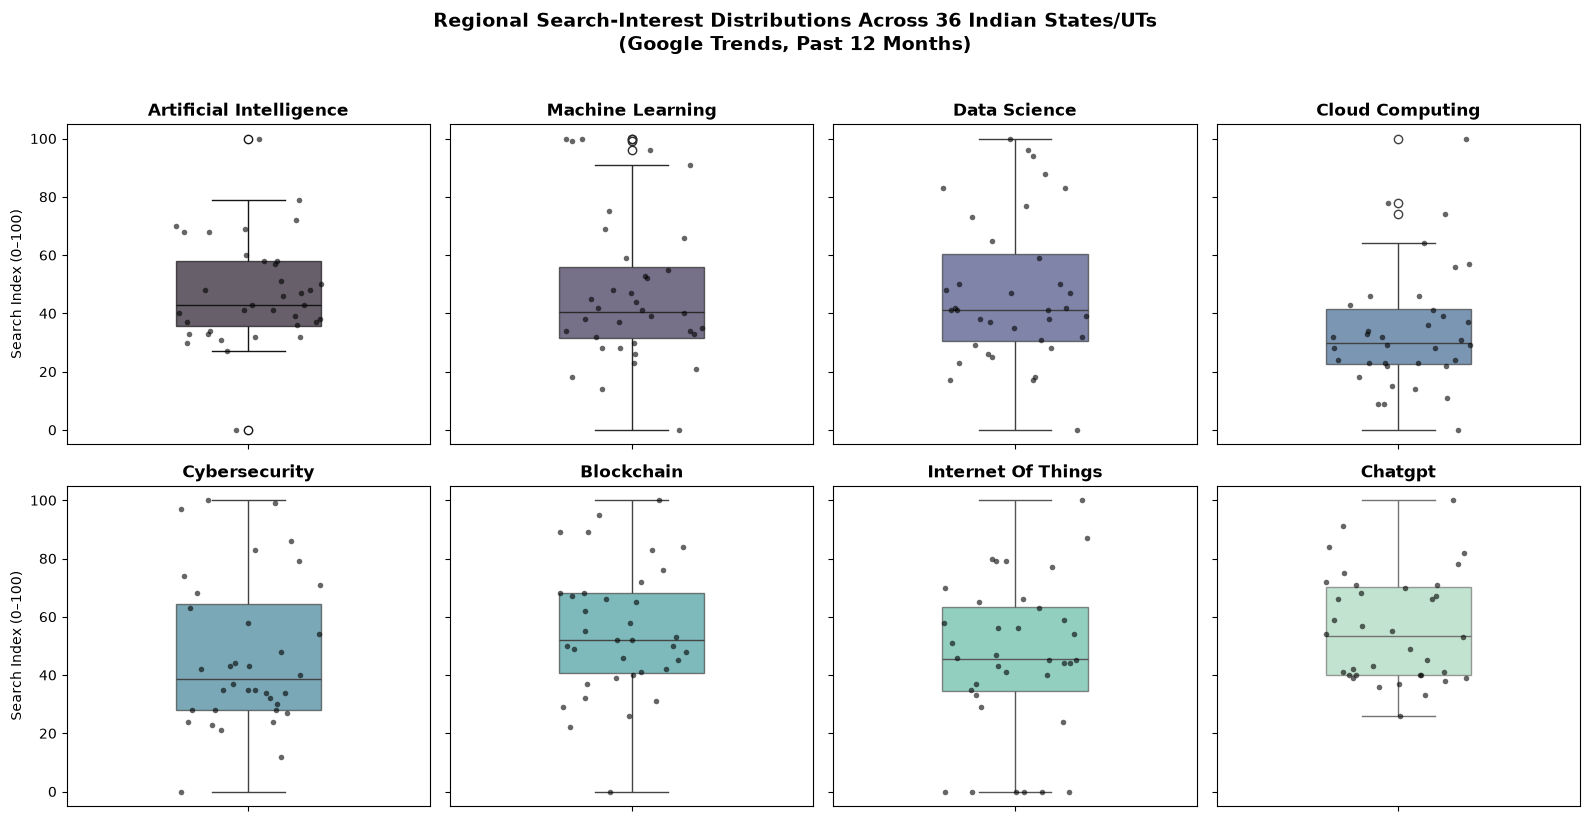

In [8]:
# Figure 1: Topic Distributions (Boxplots & Jittered Points)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
axes = axes.flatten()
palette = sns.color_palette("mako", n_colors=len(topic_cols))

for idx, col in enumerate(topic_cols):
    clean_title = col.replace("_", " ").title()
    sns.boxplot(
        y=df_features[col],
        ax=axes[idx],
        color=palette[idx],
        width=0.4,
        boxprops=dict(alpha=0.7)
    )
    sns.stripplot(
        y=df_features[col],
        ax=axes[idx],
        color="black",
        size=4,
        jitter=0.2,
        alpha=0.6
    )
    axes[idx].set_title(clean_title, fontweight="bold")
    axes[idx].set_ylabel("Search Index (0–100)" if idx % 4 == 0 else "")
    axes[idx].set_ylim(-5, 105)

plt.suptitle(
    "Regional Search-Interest Distributions Across 36 Indian States/UTs\n(Google Trends, Past 12 Months)",
    fontsize=14,
    fontweight="bold",
    y=1.02
)
plt.tight_layout()

# Save figure to outputs/figures/
fig_dir = os.path.join("..", "outputs", "figures")
if not os.path.exists(fig_dir):
    fig_dir = os.path.join("outputs", "figures")
os.makedirs(fig_dir, exist_ok=True)

plt.savefig(os.path.join(fig_dir, "topic_distributions.png"), dpi=300, bbox_inches="tight")
plt.show()

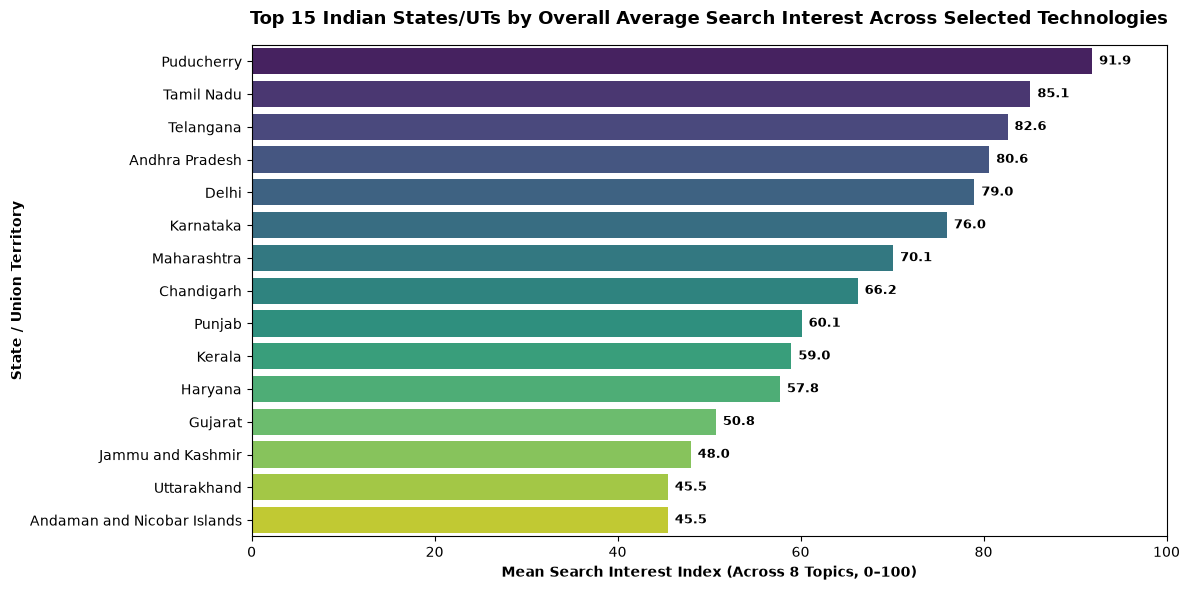

In [9]:
# Figure 2: Top 15 States by Mean Emerging Technology Search Intensity
df_rank = df_raw.copy()
df_rank["mean_search_index"] = df_rank[topic_cols].mean(axis=1)
df_top15 = df_rank.sort_values(by="mean_search_index", ascending=False).head(15)

plt.figure(figsize=(12, 6))
bars = sns.barplot(
    x="mean_search_index",
    y="state",
    data=df_top15,
    palette="viridis",
    hue="state",
    legend=False
)

for bar in bars.patches:
    width = bar.get_width()
    plt.annotate(
        f"{width:.1f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(5, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title(
    "Top 15 Indian States/UTs by Overall Average Search Interest Across Selected Technologies",
    fontsize=13,
    fontweight="bold",
    pad=15
)
plt.xlabel("Mean Search Interest Index (Across 8 Topics, 0–100)", fontweight="bold")
plt.ylabel("State / Union Territory", fontweight="bold")
plt.xlim(0, 100)
plt.tight_layout()

plt.savefig(os.path.join(fig_dir, "state_tech_interest_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

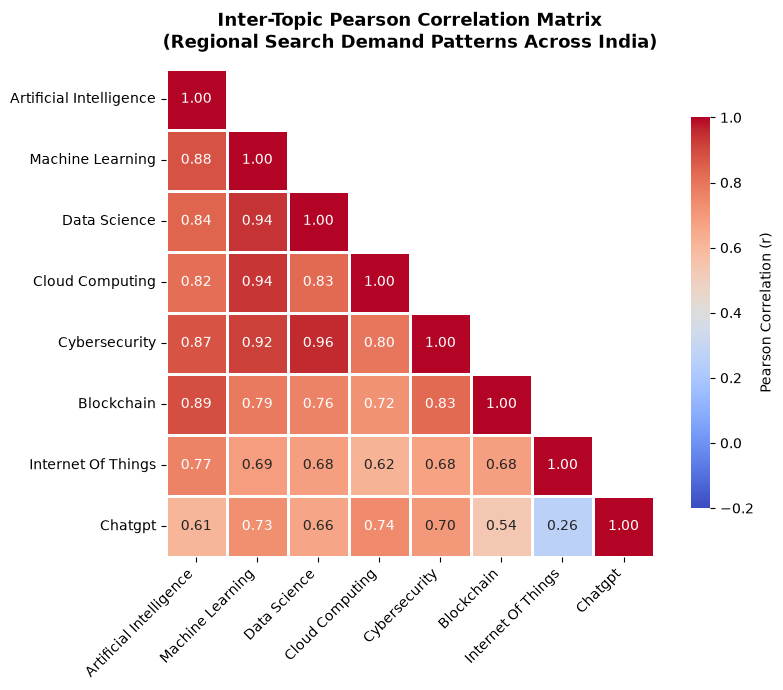

In [10]:
# Figure 3: Topic Correlation Heatmap
corr_matrix = df_features.corr()
clean_labels = [c.replace("_", " ").title() for c in corr_matrix.columns]

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.2,
    vmax=1.0,
    square=True,
    linewidths=0.8,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation (r)"},
    xticklabels=clean_labels,
    yticklabels=clean_labels
)

plt.title(
    "Inter-Topic Pearson Correlation Matrix\n(Regional Search Demand Patterns Across India)",
    fontsize=13,
    fontweight="bold",
    pad=15
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(os.path.join(fig_dir, "topic_correlation_heatmap.png"), dpi=300, bbox_inches="tight")
plt.show()

### Key Insights from Exploratory Data Analysis:
1. **Strong Core Clusters:** High positive correlations exist between foundational advanced computing topics:
   - `artificial_intelligence` and `machine_learning` ($r = 0.88$)
   - `artificial_intelligence` and `blockchain` ($r = 0.89$)
   - `machine_learning` and `data_science` ($r = 0.88$)
   - `cloud_computing` and `cybersecurity` ($r = 0.82$)
2. **Distinct Consumer / IoT Dimension:** 
   - `chatgpt` shows a moderate correlation with specialized topics ($r \approx 0.54 - 0.74$), indicating widespread general public curiosity rather than niche developer interest.
   - `internet_of_things` has low correlation with `chatgpt` ($r = 0.26$), reflecting hardware/embedded systems interest that differs regionally from generative AI consumer queries.
3. **Regional Search Intensity Leaders:**
   - Leading tech hubs (Telangana, Karnataka, Andhra Pradesh, Maharashtra, Delhi, Tamil Nadu) show consistently high average search indices across multiple topics.
   - Distinct regional variation exists, supporting the premise that clustering can reveal meaningful segmentation.

In [11]:
# Export processed datasets to data/processed/
proc_dir = os.path.join("..", "data", "processed")
if not os.path.exists(proc_dir):
    proc_dir = os.path.join("data", "processed")
os.makedirs(proc_dir, exist_ok=True)

# 1. Combined table with identifiers, raw features, and scaled features
df_combined_export = pd.concat([df_identifiers, df_features], axis=1)
for col in topic_cols:
    df_combined_export[f"{col}_scaled"] = df_scaled[col].values

comb_file = os.path.join(proc_dir, "google_trends_processed_india.csv")
df_combined_export.to_csv(comb_file, index=False)
print(f"Exported combined processed data to: {comb_file} ({df_combined_export.shape})")

# 2. Scaled features with state as index (clustering matrix)
scaled_file = os.path.join(proc_dir, "features_scaled.csv")
df_scaled.to_csv(scaled_file)
print(f"Exported scaled clustering matrix to: {scaled_file} ({df_scaled.shape})")

Exported combined processed data to: ..\data\processed\google_trends_processed_india.csv ((36, 18))
Exported scaled clustering matrix to: ..\data\processed\features_scaled.csv ((36, 8))


## 11. Day 2 Milestone Summary & Day 3 Plan

### Summary of Day 2 Accomplishments:
1. **Data Integrity Validated:** Confirmed 0 null values, 0 duplicate rows, and preserved all 36 Indian administrative regions.
2. **Identifier Separation:** Separated regional metadata (`state`, `geo_code`) from numerical features to prevent distortion of distance metrics.
3. **Categorical Justification:** Documented why One-Hot Encoding states is mathematically counter-productive for clustering.
4. **Feature Standardization:** Standardized all 8 technology dimensions using `StandardScaler` (mean=0, std=1), ensuring equal weighting in Euclidean distance calculations.
5. **Exploratory Data Analysis:** Produced distribution box plots, state search rankings, and an inter-topic correlation heatmap.
6. **Processed Data Export:** Saved clean datasets to `data/processed/google_trends_processed_india.csv` and `data/processed/features_scaled.csv`.

### Strictly Deferred to Day 3 (Awaiting 'Start Day 3'):
- K-Means experiments across multiple values of $K$ ($K=2, 3, 4, 5$).
- Calculating validation metrics: Within-Cluster Sum of Squares (WCSS / Inertia), Silhouette Scores, and Davies-Bouldin Index.
- Generating the Elbow Method plot.
- Distance metric comparison (Euclidean vs. Manhattan geometry, K-Medoids).
- Principal Component Analysis (PCA) 2D dimensionality reduction and cluster visualization.

---
*End of Day 2. Awaiting explicit instruction: 'Start Day 3'*